# CP5408 Practical 3: Risk Metrics Notebook (student version)

This notebook calculates cybersecurity risk metrics from a small set of base inputs.

**How to use this notebook**
1. Run the setup cell (Section 0).
2. Edit the input table in Section 1. This is the only cell you need to change.
3. Run the remaining cells from top to bottom (or use *Run All*).
4. Do not type calculated values such as ALE yourself. They are generated automatically.

Each chart is also saved as a PNG file next to this notebook (for example `fig1_ale_ranking.png`) so that you can insert it into your Assignment 1 report.

For Assignment 1, replace the example risks with three priority risks from your own risk register, and submit the notebook with your report.

## 0. Setup

Run this cell first. You do not need to edit it, except to set `SAVE_FIGURES = False` if you do not want PNG files written.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)

SAVE_FIGURES = True
dollars = FuncFormatter(lambda v, _: f'${v:,.0f}')

# Same five-point scale as Practical 2
LIKELIHOOD_LABELS = ['1 Rare', '2 Unlikely', '3 Possible', '4 Likely', '5 Almost certain']
IMPACT_LABELS = ['1 Trivial', '2 Minor', '3 Moderate', '4 Serious', '5 Severe']

def finish(fig_name):
    # Tidy the current figure, optionally save it as a PNG, then display it.
    plt.tight_layout()
    if SAVE_FIGURES:
        plt.savefig(f'{fig_name}.png', dpi=200, bbox_inches='tight')
    plt.show()

## 1. Input table

Edit the values in this table only. These are the base assumptions for your risks. To add a risk, copy one `{ ... },` block and change its values.

| Column | Meaning |
|---|---|
| `ARO` | Expected number of events per year. `0.25` = once every four years, `1.0` = once a year, `2.0` = twice a year. |
| `SLE` | Estimated loss from one event, in dollars. Type `500000`, not `500,000` or `$500000`. |
| `Likelihood_1_to_5`, `Impact_1_to_5` | The ratings from your Practical 2 register (1 = Rare / Trivial, 5 = Almost certain / Severe). |
| `Treatment_Option` | Avoid, Reduce likelihood, Reduce impact, Transfer, Accept, or a combination. |
| `Control_Cost` | Estimated **annual** cost of the control (licences, staff time, training, maintenance). |
| `Likelihood_Reduction_pct` | Estimated percentage reduction in ARO after the control. Type `40` for 40 percent, not `0.4`. |
| `Impact_Reduction_pct` | Estimated percentage reduction in SLE after the control. |

In [2]:
risk_inputs = pd.DataFrame([
    {
        'Risk_ID': 'R1',
        'Risk_Name': 'Replace with your first risk',
        'ARO': 0.2,
        'SLE': 1500000,
        'Likelihood_1_to_5': 3,
        'Impact_1_to_5': 5,
        'Treatment_Option': 'Reduce likelihood',
        'Control_Name': 'Replace with proposed control',
        'Control_Cost': 120000,
        'Likelihood_Reduction_pct': 45,
        'Impact_Reduction_pct': 20,
    },
    {
        'Risk_ID': 'R2',
        'Risk_Name': 'Replace with your second risk',
        'ARO': 1.5,
        'SLE': 80000,
        'Likelihood_1_to_5': 5,
        'Impact_1_to_5': 3,
        'Treatment_Option': 'Reduce likelihood',
        'Control_Name': 'Replace with proposed control',
        'Control_Cost': 60000,
        'Likelihood_Reduction_pct': 55,
        'Impact_Reduction_pct': 10,
    },
    {
        'Risk_ID': 'R3',
        'Risk_Name': 'Replace with your third risk',
        'ARO': 0.4,
        'SLE': 300000,
        'Likelihood_1_to_5': 3,
        'Impact_1_to_5': 4,
        'Treatment_Option': 'Reduce impact / Transfer',
        'Control_Name': 'Replace with proposed control',
        'Control_Cost': 90000,
        'Likelihood_Reduction_pct': 25,
        'Impact_Reduction_pct': 35,
    },
])

risk_inputs

,Risk_ID,Risk_Name,ARO,SLE,Likelihood_1_to_5,Impact_1_to_5,Treatment_Option,Control_Name,Control_Cost,Likelihood_Reduction_pct,Impact_Reduction_pct
0,R1,Replace with your first risk,0.20,1500000,3,5,Reduce likelihood,Replace with proposed control,120000,45,20
1,R2,Replace with your second risk,1.50,80000,5,3,Reduce likelihood,Replace with proposed control,60000,55,10
2,R3,Replace with your third risk,0.40,300000,3,4,Reduce impact / Transfer,Replace with proposed control,90000,25,35


## 2. Check the inputs

This cell checks for common input problems. Run it after editing the input table. If it stops with a message, fix the input table and run it again.

In [3]:
required_columns = [
    'Risk_ID', 'Risk_Name', 'ARO', 'SLE', 'Likelihood_1_to_5', 'Impact_1_to_5',
    'Treatment_Option', 'Control_Name', 'Control_Cost',
    'Likelihood_Reduction_pct', 'Impact_Reduction_pct'
]
numeric_columns = ['ARO', 'SLE', 'Likelihood_1_to_5', 'Impact_1_to_5', 'Control_Cost',
                   'Likelihood_Reduction_pct', 'Impact_Reduction_pct']

missing = [col for col in required_columns if col not in risk_inputs.columns]
if missing:
    raise ValueError(f'Missing required columns: {missing}')

not_numeric = [col for col in numeric_columns if not pd.api.types.is_numeric_dtype(risk_inputs[col])]
if not_numeric:
    raise ValueError(f'These columns must contain plain numbers (no quotes, commas or $ signs): {not_numeric}')

duplicates = risk_inputs.loc[risk_inputs['Risk_ID'].duplicated(), 'Risk_ID'].tolist()
if duplicates:
    raise ValueError(f'Each Risk_ID must be unique. Duplicated: {duplicates}')

checks = {
    'ARO must be zero or more': (risk_inputs['ARO'] >= 0).all(),
    'SLE must be zero or more': (risk_inputs['SLE'] >= 0).all(),
    'Control_Cost must be zero or more': (risk_inputs['Control_Cost'] >= 0).all(),
    'Likelihood_1_to_5 must be a whole number from 1 to 5': risk_inputs['Likelihood_1_to_5'].isin([1, 2, 3, 4, 5]).all(),
    'Impact_1_to_5 must be a whole number from 1 to 5': risk_inputs['Impact_1_to_5'].isin([1, 2, 3, 4, 5]).all(),
    'Likelihood_Reduction_pct must be between 0 and 100': risk_inputs['Likelihood_Reduction_pct'].between(0, 100).all(),
    'Impact_Reduction_pct must be between 0 and 100': risk_inputs['Impact_Reduction_pct'].between(0, 100).all(),
}
failed = [message for message, passed in checks.items() if not passed]
if failed:
    raise ValueError('Input check failed: ' + '; '.join(failed))

# Warnings: these do not stop the notebook, but are usually mistakes.
for col in ['Likelihood_Reduction_pct', 'Impact_Reduction_pct']:
    small = risk_inputs[(risk_inputs[col] > 0) & (risk_inputs[col] < 1)]
    for _, row in small.iterrows():
        print(f"WARNING {row['Risk_ID']}: {col} = {row[col]}. Enter 40 for 40 percent, not 0.4.")
for _, row in risk_inputs[risk_inputs['Risk_Name'].str.len() > 40].iterrows():
    print(f"WARNING {row['Risk_ID']}: Risk_Name is long and may be cut off on charts. Aim for under 40 characters.")
for _, row in risk_inputs[risk_inputs['Risk_Name'].str.startswith('Replace with')].iterrows():
    print(f"NOTE {row['Risk_ID']}: still using the placeholder risk name.")

print('Input checks passed.')

NOTE R1: still using the placeholder risk name.
NOTE R2: still using the placeholder risk name.
NOTE R3: still using the placeholder risk name.
Input checks passed.


## 3. Calculate the risk metrics

This cell calculates all derived values. You do not need to edit it.

| Value | Formula |
|---|---|
| ALE | ARO × SLE |
| Residual ARO | ARO × (1 − likelihood reduction) |
| Residual SLE | SLE × (1 − impact reduction) |
| Residual ALE | Residual ARO × Residual SLE |
| Risk reduction | ALE − Residual ALE |
| Net benefit | Risk reduction − Control cost (this is the security ROI idea from the Week 3 seminar) |
| Benefit-cost ratio | Risk reduction ÷ Control cost |
| Qualitative score | Likelihood × Impact; bands: Extreme 20–25, High 12–19, Medium 6–11, Low 1–5 |

In [4]:
risks = risk_inputs.copy()

risks['ALE'] = risks['ARO'] * risks['SLE']

risks['Residual_ARO'] = risks['ARO'] * (1 - risks['Likelihood_Reduction_pct'] / 100)
risks['Residual_SLE'] = risks['SLE'] * (1 - risks['Impact_Reduction_pct'] / 100)
risks['Residual_ALE'] = risks['Residual_ARO'] * risks['Residual_SLE']

risks['Risk_Reduction'] = risks['ALE'] - risks['Residual_ALE']
risks['Net_Benefit'] = risks['Risk_Reduction'] - risks['Control_Cost']
risks['Benefit_Cost_Ratio'] = np.where(risks['Control_Cost'] > 0,
                                       risks['Risk_Reduction'] / risks['Control_Cost'], np.nan)

risks['Qualitative_Risk_Score'] = risks['Likelihood_1_to_5'] * risks['Impact_1_to_5']

def risk_band(score):
    if score >= 20:
        return 'Extreme'
    if score >= 12:
        return 'High'
    if score >= 6:
        return 'Medium'
    return 'Low'

risks['Qualitative_Risk_Band'] = risks['Qualitative_Risk_Score'].apply(risk_band)
risks['Label'] = risks['Risk_ID'] + ' - ' + risks['Risk_Name']

risks_sorted = risks.sort_values('ALE', ascending=False).reset_index(drop=True)
print(f'Calculated metrics for {len(risks)} risks.')

Calculated metrics for 3 risks.


## 4. Summary tables

These two tables contain the values most relevant to Assignment 1. Both are generated from your input table. They are also saved as `risk_summary.csv`.

In [5]:
before_columns = ['Risk_ID', 'Risk_Name', 'ARO', 'SLE', 'ALE', 'Qualitative_Risk_Score', 'Qualitative_Risk_Band']
risks_sorted[before_columns]

,Risk_ID,Risk_Name,ARO,SLE,ALE,Qualitative_Risk_Score,Qualitative_Risk_Band
0,R1,Replace with your first risk,0.20,1500000,"300,000.00",15,High
1,R2,Replace with your second risk,1.50,80000,"120,000.00",15,High
2,R3,Replace with your third risk,0.40,300000,"120,000.00",12,High


In [6]:
after_columns = ['Risk_ID', 'Control_Name', 'Control_Cost', 'Residual_ARO', 'Residual_SLE',
                 'Residual_ALE', 'Risk_Reduction', 'Net_Benefit', 'Benefit_Cost_Ratio']
if SAVE_FIGURES:
    risks_sorted.drop(columns=['Label']).to_csv('risk_summary.csv', index=False)
risks_sorted[after_columns]

,Risk_ID,Control_Name,Control_Cost,Residual_ARO,Residual_SLE,Residual_ALE,Risk_Reduction,Net_Benefit,Benefit_Cost_Ratio
0,R1,Replace with proposed control,120000,0.11,"1,200,000.00","132,000.00","168,000.00","48,000.00",1.40
1,R2,Replace with proposed control,60000,0.67,"72,000.00","48,600.00","71,400.00","11,400.00",1.19
2,R3,Replace with proposed control,90000,0.30,"195,000.00","58,500.00","61,500.00","-28,500.00",0.68


## 5. Figure 1: ALE ranking

Ranks risks by expected annual loss before treatment.

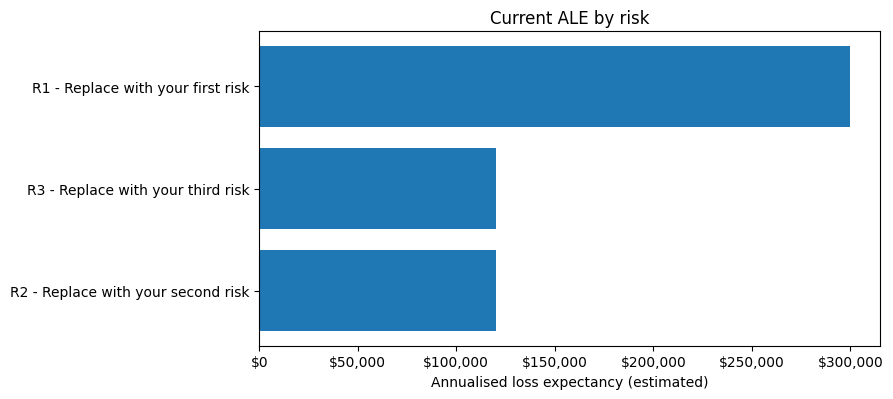

In [7]:
plot_data = risks_sorted.sort_values('ALE')

fig, ax = plt.subplots(figsize=(9, 0.7 * len(plot_data) + 2))
ax.barh(plot_data['Label'], plot_data['ALE'])
ax.xaxis.set_major_formatter(dollars)
ax.set_xlabel('Annualised loss expectancy (estimated)')
ax.set_title('Current ALE by risk')
finish('fig1_ale_ranking')

## 6. Figure 2: Current vs residual ALE

Compares expected annual loss before and after the proposed treatment.

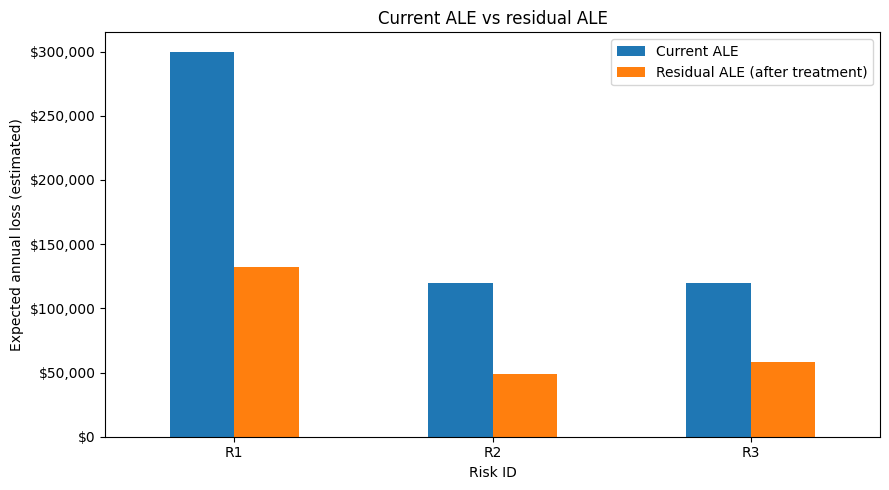

In [8]:
comparison = risks_sorted.set_index('Risk_ID')[['ALE', 'Residual_ALE']]
comparison.columns = ['Current ALE', 'Residual ALE (after treatment)']

ax = comparison.plot(kind='bar', figsize=(9, 5))
ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel('Risk ID')
ax.set_ylabel('Expected annual loss (estimated)')
ax.set_title('Current ALE vs residual ALE')
plt.xticks(rotation=0)
finish('fig2_current_vs_residual')

## 7. Figure 3: Risk reduction compared with control cost

Compares the estimated annual risk reduction with the estimated annual cost of each control. Where the cost bar is taller than the reduction bar, the control costs more than the loss it is expected to avoid.

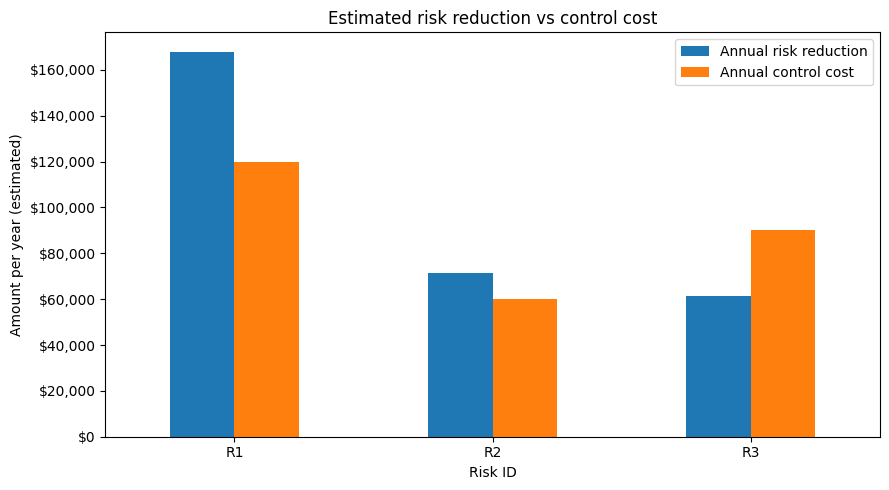

In [9]:
cost_comparison = risks_sorted.set_index('Risk_ID')[['Risk_Reduction', 'Control_Cost']]
cost_comparison.columns = ['Annual risk reduction', 'Annual control cost']

ax = cost_comparison.plot(kind='bar', figsize=(9, 5))
ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel('Risk ID')
ax.set_ylabel('Amount per year (estimated)')
ax.set_title('Estimated risk reduction vs control cost')
plt.xticks(rotation=0)
finish('fig3_reduction_vs_cost')

## 8. Figure 4: Benefit-cost ratio

A ratio above 1 means the estimated annual risk reduction is greater than the estimated annual control cost. This is not a complete decision rule: legal, ethical, safety, and reputational reasons may justify a control whose ratio is below 1.

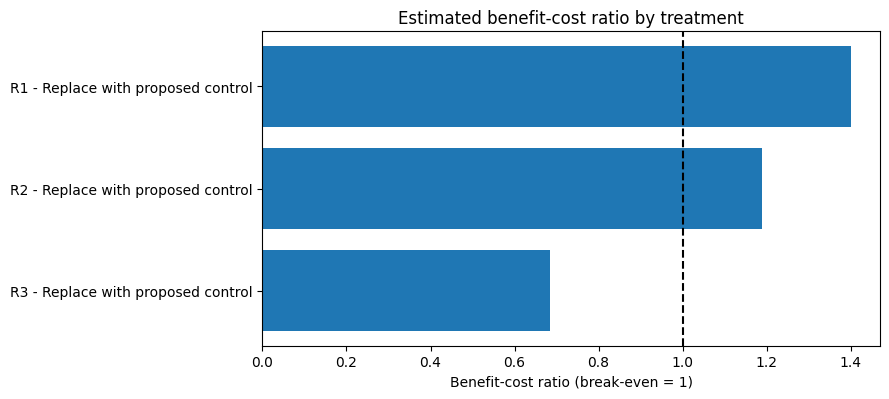

In [10]:
bcr_data = risks_sorted.dropna(subset=['Benefit_Cost_Ratio']).sort_values('Benefit_Cost_Ratio')

fig, ax = plt.subplots(figsize=(9, 0.7 * len(bcr_data) + 2))
ax.barh(bcr_data['Risk_ID'] + ' - ' + bcr_data['Control_Name'], bcr_data['Benefit_Cost_Ratio'])
ax.axvline(1, linestyle='--', color='black')
ax.set_xlabel('Benefit-cost ratio (break-even = 1)')
ax.set_title('Estimated benefit-cost ratio by treatment')
finish('fig4_benefit_cost_ratio')

## 9. Figure 5: Exposure bubble chart

Shows ARO (x-axis), SLE (y-axis) and ALE (bubble size) together. It separates risks that are rare but severe from those that are frequent but smaller, even when their ALE is the same.

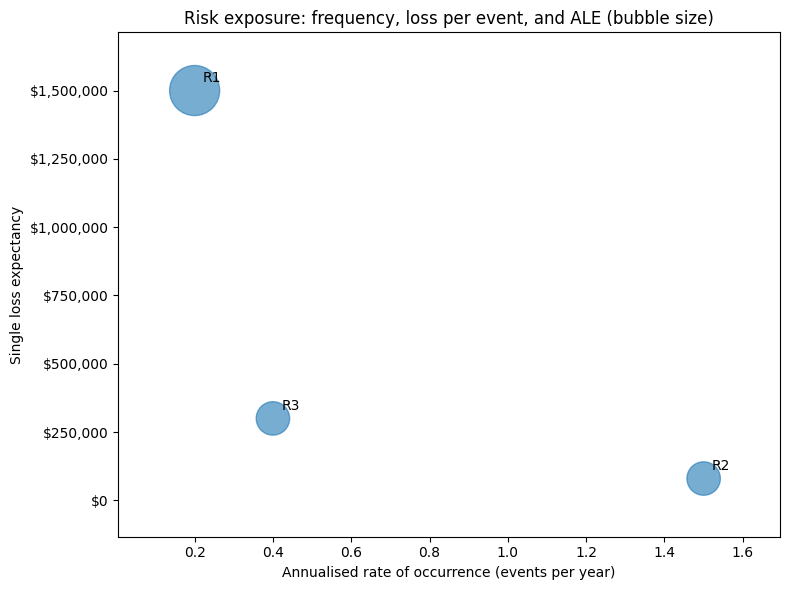

In [11]:
max_ale = risks['ALE'].max()
bubble_sizes = (risks['ALE'] / max_ale) * 1200 + 100 if max_ale > 0 else 300

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(risks['ARO'], risks['SLE'], s=bubble_sizes, alpha=0.6)
for _, row in risks.iterrows():
    ax.annotate(row['Risk_ID'], (row['ARO'], row['SLE']), textcoords='offset points', xytext=(6, 6))
ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel('Annualised rate of occurrence (events per year)')
ax.set_ylabel('Single loss expectancy')
ax.set_title('Risk exposure: frequency, loss per event, and ALE (bubble size)')
ax.margins(0.15)
finish('fig5_exposure_bubble')

## 10. Figure 6: Qualitative risk heatmap

Uses the `Likelihood_1_to_5` and `Impact_1_to_5` ratings and the same colour bands as the Practical 2 matrix. Risks that share a cell are listed together.

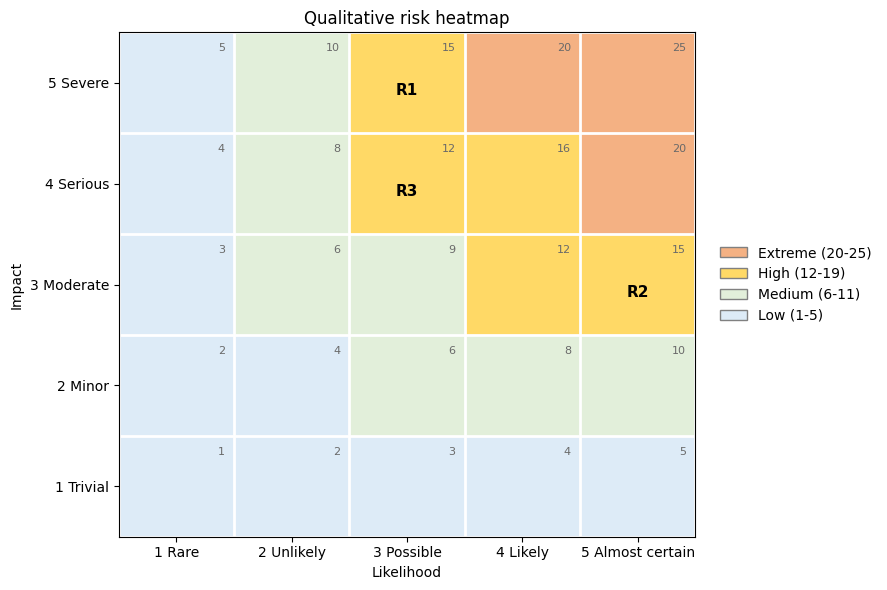

In [12]:
# Score grid with impact 5 on the top row
scores = np.array([[impact * likelihood for likelihood in range(1, 6)] for impact in range(5, 0, -1)])

band_colours = ['#DDEBF7', '#E2EFDA', '#FFD966', '#F4B183']   # Low, Medium, High, Extreme
cmap = ListedColormap(band_colours)
norm = BoundaryNorm([0, 5.5, 11.5, 19.5, 25.5], cmap.N)

fig, ax = plt.subplots(figsize=(9, 6))
ax.imshow(scores, cmap=cmap, norm=norm, aspect='auto')
ax.set_xticks(range(5))
ax.set_xticklabels(LIKELIHOOD_LABELS)
ax.set_yticks(range(5))
ax.set_yticklabels(IMPACT_LABELS[::-1])
ax.set_xlabel('Likelihood')
ax.set_ylabel('Impact')
ax.set_title('Qualitative risk heatmap')

# White grid lines between cells
ax.set_xticks(np.arange(-0.5, 5, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 5, 1), minor=True)
ax.grid(which='minor', color='white', linewidth=2)
ax.tick_params(which='minor', length=0)

# Small score in the corner of each cell
for r in range(5):
    for col in range(5):
        ax.text(col + 0.42, r - 0.34, str(scores[r, col]), ha='right', va='center', fontsize=8, color='dimgray')

# Risk IDs, grouped so that risks sharing a cell do not overlap
def cell_label(ids):
    ids = list(ids)
    return '\n'.join(', '.join(ids[i:i + 2]) for i in range(0, len(ids), 2))   # two IDs per line

grouped = risks.groupby(['Likelihood_1_to_5', 'Impact_1_to_5'])['Risk_ID'].apply(cell_label)
for (likelihood, impact), label in grouped.items():
    crowded = label.count(',') + label.count('\n') >= 2
    ax.text(likelihood - 1, 5 - impact + 0.08, label, ha='center', va='center',
            fontweight='bold', fontsize=8.5 if crowded else 11)

legend_items = [Patch(facecolor=colour, edgecolor='gray', label=name) for colour, name in
                zip(band_colours[::-1], ['Extreme (20-25)', 'High (12-19)', 'Medium (6-11)', 'Low (1-5)'])]
ax.legend(handles=legend_items, loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False)
finish('fig6_heatmap')

## 11. Optional: incident-handling metrics

The Week 3 seminar also covered incident handling. This section shows how simple monthly measurements become metrics when tracked over time. Edit the table only if you want to use different data. These charts are not required for Assignment 1, but they may support discussion of monitoring, detection, and response capability in your strategy.

In [13]:
incident_inputs = pd.DataFrame({
    'Month': ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun'],
    'Security_Events': [420, 510, 470, 620, 580, 530],
    'Confirmed_Incidents': [8, 9, 7, 12, 10, 8],
    'Mean_Time_To_Detect_Hours': [38, 34, 29, 26, 22, 18],
    'Mean_Time_To_Recover_Hours': [72, 68, 60, 55, 48, 42]
})

incidents = incident_inputs.copy()
incidents['Incidents_per_100_Events'] = np.where(incidents['Security_Events'] > 0,
    incidents['Confirmed_Incidents'] / incidents['Security_Events'] * 100, np.nan)
incidents

,Month,Security_Events,Confirmed_Incidents,Mean_Time_To_Detect_Hours,Mean_Time_To_Recover_Hours,Incidents_per_100_Events
0,Jan,420,8,38,72,1.90
1,Feb,510,9,34,68,1.76
2,Mar,470,7,29,60,1.49
3,Apr,620,12,26,55,1.94
4,May,580,10,22,48,1.72
5,Jun,530,8,18,42,1.51


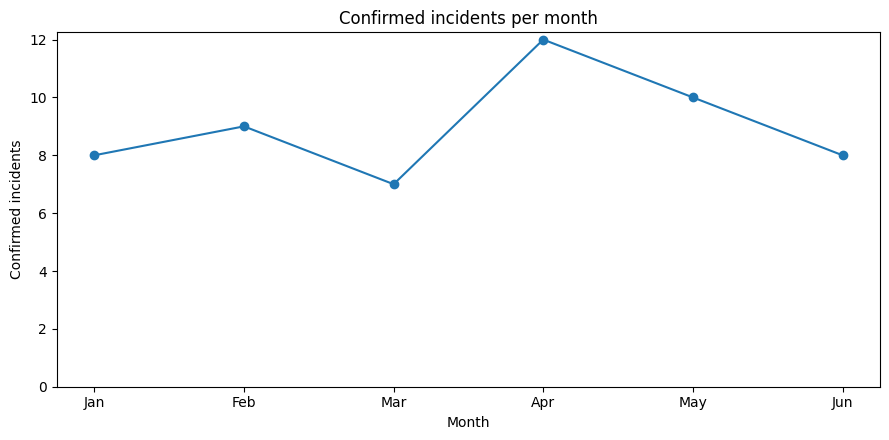

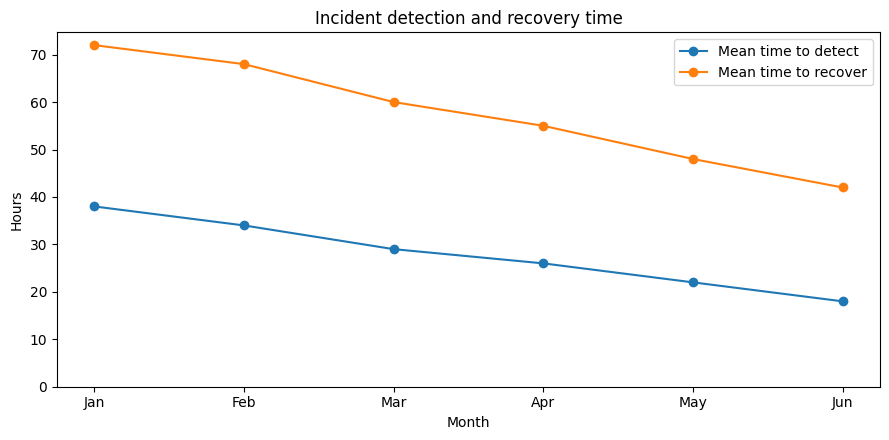

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(incidents['Month'], incidents['Confirmed_Incidents'], marker='o')
ax.set_ylim(bottom=0)
ax.set_xlabel('Month')
ax.set_ylabel('Confirmed incidents')
ax.set_title('Confirmed incidents per month')
finish('fig7_incident_counts')

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(incidents['Month'], incidents['Mean_Time_To_Detect_Hours'], marker='o', label='Mean time to detect')
ax.plot(incidents['Month'], incidents['Mean_Time_To_Recover_Hours'], marker='o', label='Mean time to recover')
ax.set_ylim(bottom=0)
ax.set_xlabel('Month')
ax.set_ylabel('Hours')
ax.set_title('Incident detection and recovery time')
ax.legend()
finish('fig8_incident_times')

## 12. Assumptions log

Assignment 1 asks you to justify your ARO, SLE, control cost, and reduction estimates. Record the basis for each value here (double-click this cell to edit it), so that the notebook you submit explains where its numbers came from.

| Risk ID | Value | Estimate | Source or reasoning | Confidence (low / medium / high) |
|---|---|---|---|---|
| R1 | ARO |  |  |  |
| R1 | SLE |  |  |  |
| R1 | Control cost |  |  |  |
| R1 | Likelihood / impact reduction |  |  |  |
|  |  |  |  |  |